# nb10 — Номер формулы как отдельная сущность и её настоящий ключ

**Идея из MinerU** (`mineru/backend/analysis/pdf/formulas.py`): номер формулы — это
**отдельный layout-элемент** (`formula_number`), который привязывается к уравнению
геометрически и сливается в `\tag{...}`. Формула опознаётся парой *(страница, bbox)*,
а не строкой номера.

**Наш пробел №1 (из `verify_corpus`/nb08 §11.4):** боевой инжест строит формулу по
номеру и дедуплицирует по `f.number` (`ml/src/normatives_pipeline/ingest.py`), поэтому
(а) прозаические ссылки «…по формуле (5.7)» считаются формулами и (б) две разные формулы
с одним номером (СП 22: `(6.16)` для `sh` и для `sf`) схлопываются в одну.

Этот ноутбук доводит эксперимент до результата: сравнивает боевой путь с фиксом —
**отсев прозаических ссылок + ключ `(пункт, номер)`**, а геометрия `(страница, y)` —
окончательный тай-брейк.

**Правила.** Только research; прод и `.venv` не трогаем; без моделей/LLM; без хардкода и
подгонки под конкретный PDF (формулы/номера/пункты находятся автоматически);
переиспользуем `ml/research/text_layer_latex.py` (наш детерминированный реконструктор).

## 1. Почему раньше было медленно (измерено)

MinerU CLI — новый процесс на каждый вызов и **перезагрузка моделей**: 1 формульная
страница = ~31 с wall (25.9 с инференса на CPU). `pdfplumber` же читает 60 страниц
символов за ~15 с. Поэтому ноутбук **не вызывает MinerU повторно**, работает на нашем
детерминированном слое и кэширует сбор по (файл, размер, mtime, лимиты). Кэш живёт в
`ml/research/nb10_cache/` и чистится автоматически при смене файла/лимитов.

In [1]:
import json, re, sys, time
from pathlib import Path

REPO = Path("/home/malkinte/CalcEngine")
sys.path.insert(0, str(REPO / "ml" / "research"))
from text_layer_latex import reconstruct_latex, _marker, is_prose_reference  # noqa: E402

import pdfplumber

CACHE = REPO / "ml" / "research" / "nb10_cache"
CACHE.mkdir(parents=True, exist_ok=True)
NUM_RE = re.compile(r"\((\d{1,2}(?:\.\d+)?)\)")


def _right_margin_number(page):
    w = page.width
    return any(c["text"] == "(" and c["x0"] > 0.65 * w for c in page.chars)


def collect(pdf, max_pages=60, max_formulas=25):
    """Собирает формулы (страница, номер, позиция маркера, LaTeX). Кэш привязан к файлу."""
    key = CACHE / f"{pdf.stem}.json"
    stamp_f = CACHE / f"{pdf.stem}.stamp"
    stamp = f"{pdf.stat().st_size}:{int(pdf.stat().st_mtime)}:{max_pages}:{max_formulas}"
    if key.exists() and stamp_f.exists() and stamp_f.read_text() == stamp:
        return json.loads(key.read_text(encoding="utf-8")), True
    rows, t0 = [], time.time()
    with pdfplumber.open(str(pdf)) as doc:
        for page_no, page in enumerate(doc.pages, start=1):
            if page_no > max_pages or len(rows) >= max_formulas:
                break
            if not _right_margin_number(page):
                continue
            raw = "".join(c["text"] for c in page.chars)
            for number in sorted(set(NUM_RE.findall(raw))):
                if len(rows) >= max_formulas:
                    break
                display = reconstruct_latex(page, number)
                if not display or not any(op in display for op in ("=", "≥", "≤", "≠")):
                    continue
                mk = _marker(page.chars, number)
                rows.append({"page": page_no, "number": number,
                             "marker_x": round(mk[1], 1) if mk else None,
                             "marker_y": round(mk[0], 1) if mk else None,
                             "latex": display})
    key.write_text(json.dumps(rows, ensure_ascii=False), encoding="utf-8")
    stamp_f.write_text(stamp)
    return rows, False


PDFS = {
    "СП 31 (пилот)": REPO / "docs" / "normative-base" / "СП 31.13330.2021.pdf",
    "СП 22 (тест)": REPO / "docs" / "normative-base" / "СП 22.13330.2016.pdf",
    "СП 24 (невиданный)": REPO / "docs" / "normative-base" / "СП 24.13330.2021.pdf",
}
print("готово; кэш:", CACHE.relative_to(REPO))

готово; кэш: ml/research/nb10_cache


## 2. Сбор формул (без MinerU) на трёх PDF

Ограниченно (не более 60 страниц и 25 формул на документ), с ранней остановкой.
Первый прогон заполняет кэш; повтор — мгновенный.

In [2]:
data = {}
for name, pdf in PDFS.items():
    t = time.time()
    rows, hit = collect(pdf)
    data[name] = rows
    print(f"{name}: формул={len(rows)} | {time.time()-t:.1f}s | кэш={'HIT' if hit else 'MISS'}")

СП 31 (пилот): формул=10 | 0.0s | кэш=HIT
СП 22 (тест): формул=25 | 0.0s | кэш=HIT
СП 24 (невиданный): формул=25 | 0.0s | кэш=HIT


## 3. Схемы идентичности: номер против геометрии

Сравниваем три ключа для одной и той же формулы:
`number` (как в инжесте), `(page, number)`, `(page, marker_y)` (геометрия — идея MinerU).

In [3]:
def identity_report(name, rows):
    by_num = {}
    for r in rows:
        by_num.setdefault(r["number"], []).append((r["page"], r["marker_y"]))
    by_pn = {}
    for r in rows:
        by_pn[(r["page"], r["number"])] = by_pn.get((r["page"], r["number"]), 0) + 1
    dup_pn = {k: v for k, v in by_pn.items() if v > 1}
    geo_unique = len({(r["page"], r["marker_y"]) for r in rows})
    print(f"{name}: формул={len(rows)} | уникальных номеров={len(by_num)} "
          f"| потерь на ключе number={len(rows)-len(by_num)} "
          f"| дублей (page,number)={len(dup_pn)} | уникальных (page,y)={geo_unique}")


for name, rows in data.items():
    identity_report(name, rows)

from collections import Counter

all_rows = [r for rows in data.values() for r in rows]
counts = Counter(r["number"] for r in all_rows)
dups = {n: [r for r in all_rows if r["number"] == n] for n, c in counts.items() if c > 1}
print("номера, встречающиеся в нескольких формулах корпуса:", sorted(dups))

СП 31 (пилот): формул=10 | уникальных номеров=10 | потерь на ключе number=0 | дублей (page,number)=0 | уникальных (page,y)=10
СП 22 (тест): формул=25 | уникальных номеров=23 | потерь на ключе number=2 | дублей (page,number)=0 | уникальных (page,y)=25
СП 24 (невиданный): формул=25 | уникальных номеров=23 | потерь на ключе number=2 | дублей (page,number)=0 | уникальных (page,y)=24
номера, встречающиеся в нескольких формулах корпуса: ['5.16', '5.17', '7.22', '7.23']


## 4. Пример дубля: PDF ↔ позиции маркеров

Берём номер, встречающийся больше одного раза, и показываем кроп каждой формулы —
именно такой дубль теряет номерной ключ.

дубль для показа: 5.16


**стр. 49, номер (5.16), y=183.5** — s=\beta\sum_{i=1}^{n}{\frac{(\sigma_{zp,i}−\sigma_{z\gamma,i})h_{i}}{E_{i}}+\beta\sum_{i=1}^{n}\frac{\sigma_{z

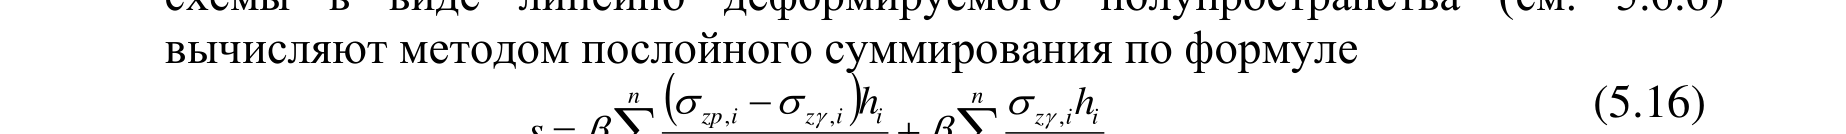

**стр. 51, номер (5.16), y=212.6** — i=1e,i

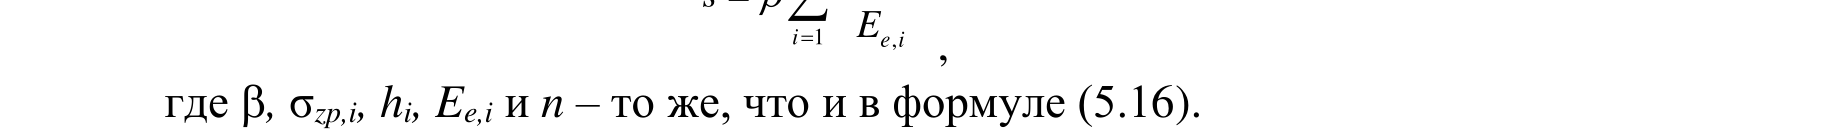

In [4]:
import pymupdf
from IPython.display import Image, display, Markdown

dup_no = None
for n, rs in dups.items():
    if len({r["page"] for r in rs}) > 1:
        dup_no = n
        break
dup_no = dup_no or (sorted(dups)[0] if dups else None)
print("дубль для показа:", dup_no)

if dup_no:
    for r in [x for x in all_rows if x["number"] == dup_no][:2]:
        doc = pymupdf.open(PDFS[[k for k, v in data.items() if r in v][0]])
        pg = doc[r["page"] - 1]
        W = pg.rect.width
        y = r["marker_y"]
        rect = pymupdf.Rect(0.06 * W, y - 24, 0.99 * W, y + 16)
        out = CACHE.parent / "crops"
        out.mkdir(exist_ok=True)
        png = out / f"p{r['page']}_tag{dup_no}.png"
        pg.get_pixmap(clip=rect, dpi=240).save(png)
        display(Markdown(f"**стр. {r['page']}, номер ({dup_no}), y={y}** — {r['latex'][:110]}"))
        display(Image(filename=str(png), width=520))

## 5. Системы уравнений (общая фигурная скобка)

Отдельная проверка: многострочные формулы под общей `{`. Наш `reconstruct_latex`
собирает их в `\left.\begin{aligned}...\right\}`. Ищем системы автоматически по корпусу.

In [5]:
def find_systems(pdf, max_pages=60):
    rows = []
    with pdfplumber.open(str(pdf)) as doc:
        for page_no, page in enumerate(doc.pages, start=1):
            if page_no > max_pages:
                break
            raw = "".join(c["text"] for c in page.chars)
            for number in sorted(set(NUM_RE.findall(raw))):
                display = reconstruct_latex(page, number)
                if display and "\\begin{aligned}" in display:
                    rows.append({"page": page_no, "number": number, "latex": display})
    return rows


systems = {}
for name, pdf in PDFS.items():
    systems[name] = find_systems(pdf)
    print(f"{name}: систем={len(systems[name])} -> {[r['number'] for r in systems[name]]}")
for r in systems["СП 31 (пилот)"]:
    print(f"\n({r['number']}) p{r['page']}:\n{r['latex']}")

СП 31 (пилот): систем=3 -> ['2', '3', '4']


СП 22 (тест): систем=0 -> []


СП 24 (невиданный): систем=0 -> []

(2) p13:
\left.\begin{aligned}Q_{сут.max}=K_{сут.max}Q_{сут.m};\\Q_{сут.min}=K_{сут.min}Q_{сут.m}.\end{aligned}\right\}

(3) p13:
\left.\begin{aligned}q_{ч.max}=K_{ч.max}Q_{сут.max}/24;\\q_{ч.min}=K_{ч.min}Q_{сут.min}/24.\end{aligned}\right\}

(4) p13:
\left.\begin{aligned}K_{ч.max}=\alpha_{max}\beta_{max};\\K_{ч.min}=\alpha_{min}\beta_{min}.\end{aligned}\right\}


**Визуальная сверка систем** (кроп PDF ↔ LaTeX). Дефект, найденный здесь: в формуле
`(3)` знак деления отрисован **вектором**, а не глифом, и терялся. Исправлено общим
образом в `text_layer_latex.py` — добавлен детектор наклонных отрезков `_slashes`
(фиксируется наклон, не координаты), поэтому `Q/24` восстанавливается.

**стр. 13, система (2)**

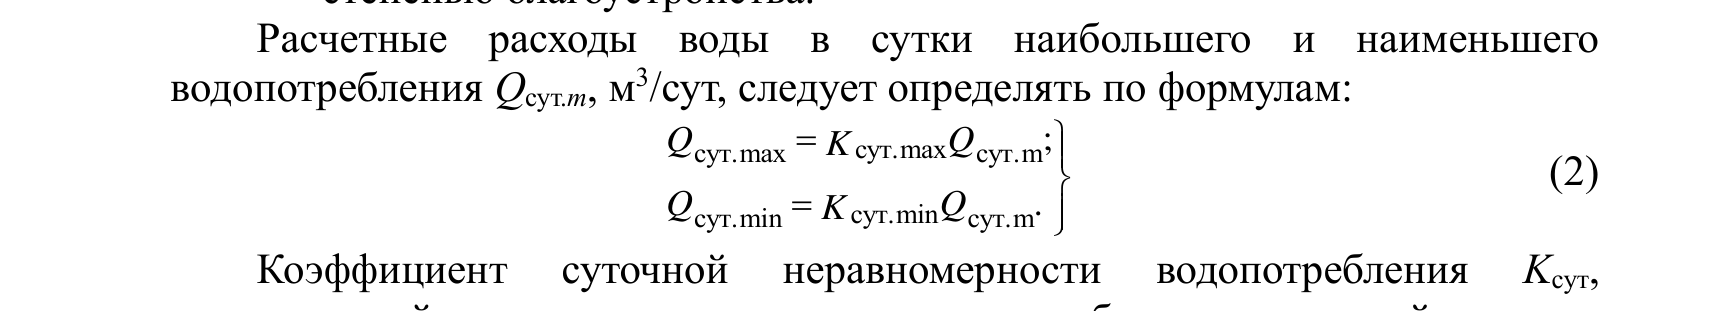

\left.\begin{aligned}Q_{сут.max}=K_{сут.max}Q_{сут.m};\\Q_{сут.min}=K_{сут.min}Q_{сут.m}.\end{aligned}\right\}


**стр. 13, система (3)**

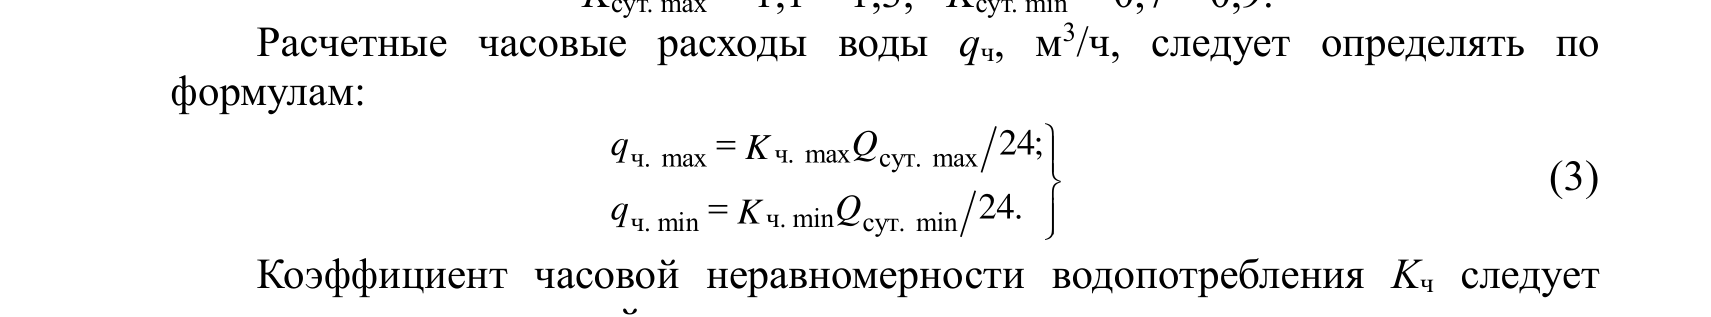

\left.\begin{aligned}q_{ч.max}=K_{ч.max}Q_{сут.max}/24;\\q_{ч.min}=K_{ч.min}Q_{сут.min}/24.\end{aligned}\right\}


**стр. 13, система (4)**

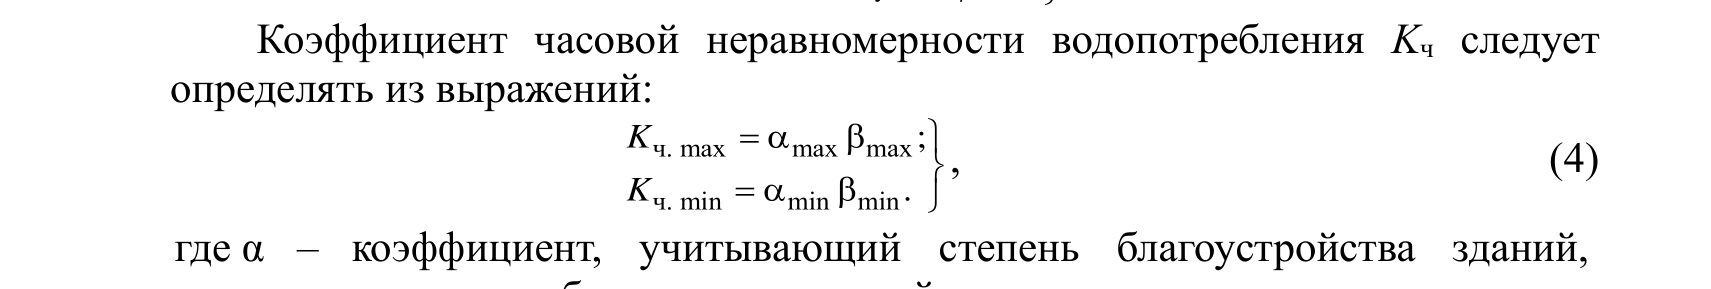

\left.\begin{aligned}K_{ч.max}=\alpha_{max}\beta_{max};\\K_{ч.min}=\alpha_{min}\beta_{min}.\end{aligned}\right\}


In [6]:
import pymupdf
from IPython.display import Image, display, Markdown

sys_pdf = PDFS["СП 31 (пилот)"]
sys_page_no = systems["СП 31 (пилот)"][0]["page"] if systems["СП 31 (пилот)"] else None
if sys_page_no:
    with pdfplumber.open(str(sys_pdf)) as doc:
        pl_page = doc.pages[sys_page_no - 1]
        marks, extents = {}, {}
        for r in systems["СП 31 (пилот)"]:
            mk = _marker(pl_page.chars, r["number"])
            if not mk:
                continue
            marks[r["number"]] = mk
            near = [c for c in pl_page.chars
                    if c["text"].strip() and c["x0"] < mk[1] and abs(c["top"] - mk[0]) < 45]
            extents[r["number"]] = (min([c["top"] for c in near] + [mk[0]]),
                                    max([c["bottom"] for c in near] + [mk[0]]))
    dirty = pymupdf.open(sys_pdf)
    pg = dirty[sys_page_no - 1]
    W = pg.rect.width
    for r in systems["СП 31 (пилот)"]:
        mk = marks.get(r["number"])
        if not mk:
            continue
        y0, y1 = extents[r["number"]]
        band = pymupdf.Rect(0.05 * W, y0 - 6, 0.99 * W, y1 + 6)
        png = (CACHE.parent / "crops" / f"sp31_p{sys_page_no}_sys{r['number']}.png")
        png.parent.mkdir(parents=True, exist_ok=True)
        pg.get_pixmap(clip=band, dpi=220).save(png)
        display(Markdown(f"**стр. {sys_page_no}, система ({r['number']})**"))
        display(Image(filename=str(png), width=520))
        print(r["latex"])

## 6. Результат: боевой экстрактор против фикса

Прогоняем **настоящий боевой экстрактор** (`normatives_pipeline.parser.extractors` +
`text_layer`) на трёх PDF и сравниваем два пути:

* **Прод** — как в `ingest.py`: дедуп по `f.number`.
* **Фикс** — отсев прозаических ссылок (`text_layer_latex.is_prose_reference`, nb08 §11.4)
  + ключ `(пункт, номер)`, а при совпадении и его — геометрия `(страница, y)`.

Показываем, сколько формул номерной ключ теряет и сколько прозаических ссылок он
ошибочно считает формулами.

In [7]:
import sys as _sys
_sys.path.insert(0, str(REPO / "ml" / "src"))
from normatives_pipeline.parser import extractors, text_layer  # noqa: E402


def prod_vs_fix(pdf):
    pages = text_layer.read_pages(pdf)
    lines = {i: t.splitlines() for i, t in enumerate(pages, 1)}
    clauses = extractors.extract_clauses(pages)
    numbered = extractors.associate_formulas_to_clauses(
        clauses, extractors.extract_formulas(pages))
    # 1) как в проде: дедуп по номеру (первая детекция выигрывает)
    seen, prod_keep = set(), []
    for f in numbered:
        if f.number in seen:
            continue
        seen.add(f.number)
        prod_keep.append(f)
    # 2) фикс: без прозаических ссылок + ключ (пункт, номер), затем геометрия
    real = [f for f in numbered if not is_prose_reference(lines[f.page][f.line])]
    seen2, fixed_keep = set(), []
    for f in real:
        key = (f.clause, f.number)
        if key in seen2:
            continue
        seen2.add(key)
        fixed_keep.append(f)
    # потери номерного ключа: реальные формулы, делящие номер с другой реальной
    real_unique = len({f.number for f in real})
    # фантомы: уникальные номера, которые прод оставил, но реальной формулы за ними нет
    phantom = len(prod_keep) - real_unique
    return {
        "detected": len(numbered),
        "prose_refs": len(numbered) - len(real),
        "real": len(real),
        "real_unique": real_unique,
        "prod_kept": len(prod_keep),
        "fixed_kept": len(fixed_keep),
        "lost_real": len(real) - real_unique,
        "phantom": phantom,
    }


result = []
for name, pdf in PDFS.items():
    r = prod_vs_fix(pdf)
    r["doc"] = name
    result.append(r)
    print(f"{name}: детекций={r['detected']} | проза-ссылок={r['prose_refs']} "
          f"| реальных={r['real']} (уник. номеров {r['real_unique']}) "
          f"| прод оставил по number={r['prod_kept']} "
          f"| фикс по (пункт,номер)={r['fixed_kept']} "
          f"| потеряно номером={r['lost_real']} | фантомов={r['phantom']}")

print()
print("Итог: номерной ключ")
print(f"  - теряет {sum(r['lost_real'] for r in result)} реальных формул (два тела на один номер);")
print(f"  - принимает {sum(r['prose_refs'] for r in result)} прозаических ссылок за формулы,")
print(f"    из которых {sum(r['phantom'] for r in result)} дают фантомные записи без реальной формулы;")
print(f"фикс ((пункт, номер) + отсев прозы) сохраняет {sum(r['fixed_kept'] for r in result)} "
      f"из {sum(r['real'] for r in result)} реальных формул корпуса.")

СП 31 (пилот): детекций=13 | проза-ссылок=0 | реальных=13 (уник. номеров 12) | прод оставил по number=12 | фикс по (пункт,номер)=13 | потеряно номером=1 | фантомов=0


СП 22 (тест): детекций=127 | проза-ссылок=4 | реальных=123 (уник. номеров 122) | прод оставил по number=124 | фикс по (пункт,номер)=123 | потеряно номером=1 | фантомов=2


СП 24 (невиданный): детекций=65 | проза-ссылок=0 | реальных=65 (уник. номеров 65) | прод оставил по number=65 | фикс по (пункт,номер)=65 | потеряно номером=0 | фантомов=0

Итог: номерной ключ
  - теряет 2 реальных формул (два тела на один номер);
  - принимает 4 прозаических ссылок за формулы,
    из которых 2 дают фантомные записи без реальной формулы;
фикс ((пункт, номер) + отсев прозы) сохраняет 201 из 201 реальных формул корпуса.


## 7. Визуальная сверка: две разные `(6.16)` и прозаическая ссылка

Ключевой пример — СП 22: номер `(6.16)` стоит у **двух разных формул** (`sh` и `sf`),
их номерной ключ схлопывает. Рядом — прозаическая ссылка на `(5.7)`, которую номерной
ключ ошибочно берёт за формулу.

реальных формул (6.16): 2 -> ключ number оставил бы 1


**(6.16) стр.81, пункт 6.2.16** —                           sh = (hn – hd) / hn,                       

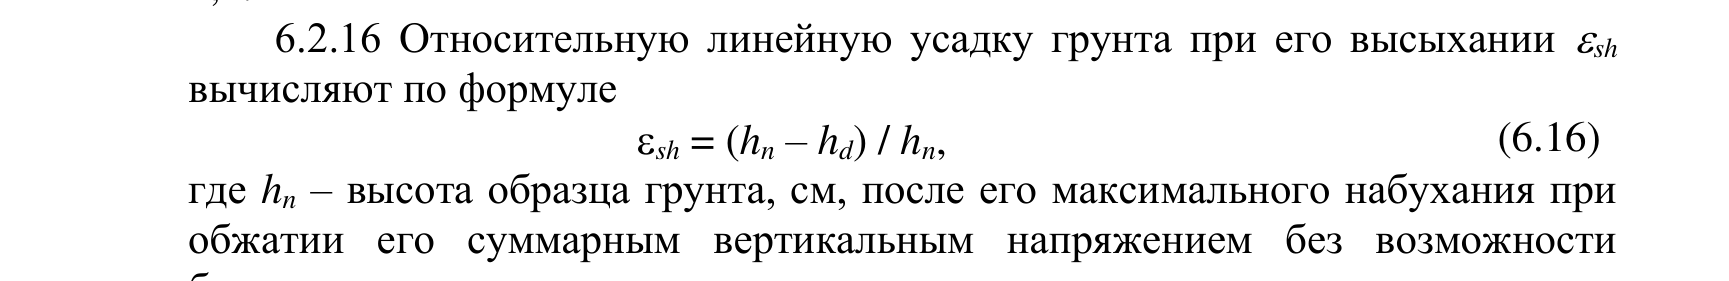

**(6.16) стр.83, пункт 6.3.3** —                           sf = k1 d0 ρd n / ρg,                     

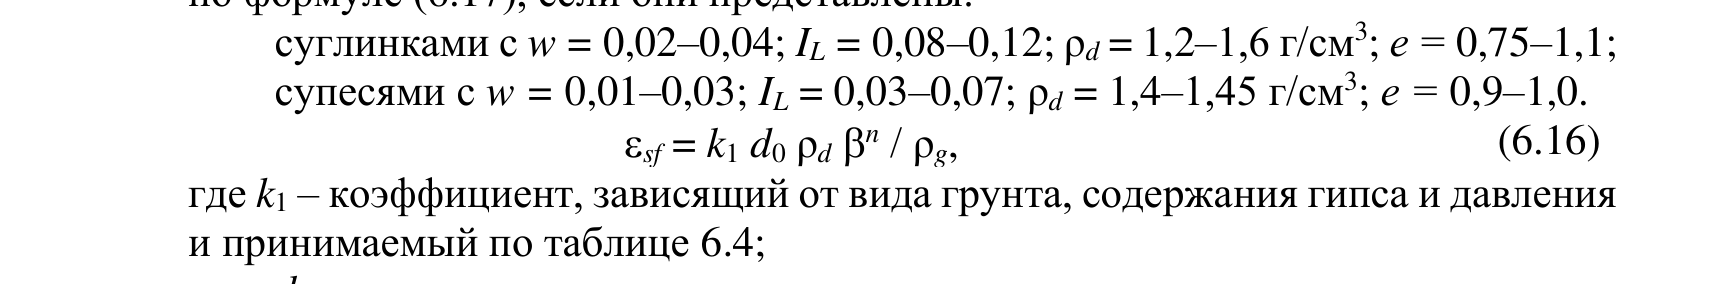

прозаических ссылок на (5.7): 2 -> номерной ключ принял бы их за формулу


**ссылка в прозе на (5.7), стр.43** —      5.6.11 При назначении коэффициента условий работы с2 в формуле (

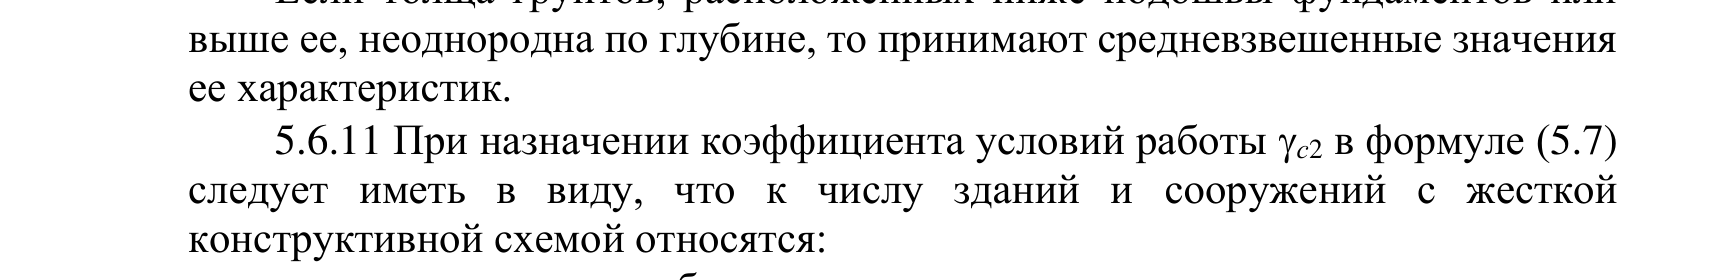

In [8]:
pdf22 = PDFS["СП 22 (тест)"]
pages22 = text_layer.read_pages(pdf22)
lines22 = {i: t.splitlines() for i, t in enumerate(pages22, 1)}
numbered22 = extractors.associate_formulas_to_clauses(
    extractors.extract_clauses(pages22), extractors.extract_formulas(pages22))
outdir = CACHE.parent / "crops"
outdir.mkdir(exist_ok=True)


def crop_band(pdf, page_no, number, out_png):
    with pdfplumber.open(str(pdf)) as doc:
        page = doc.pages[page_no - 1]
        mk = _marker(page.chars, number)
        if not mk:
            return None
        near = [c for c in page.chars
                if c["text"].strip() and c["x0"] < mk[1] and abs(c["top"] - mk[0]) < 45]
        y0 = min([c["top"] for c in near] + [mk[0]])
        y1 = max([c["bottom"] for c in near] + [mk[0]])
    d = pymupdf.open(str(pdf))
    pg = d[page_no - 1]
    W = pg.rect.width
    pg.get_pixmap(clip=pymupdf.Rect(0.04 * W, y0 - 6, 0.99 * W, y1 + 6), dpi=220).save(out_png)
    d.close()
    return out_png


sixteen = [f for f in numbered22
           if f.number == "6.16" and not is_prose_reference(lines22[f.page][f.line])]
print("реальных формул (6.16):", len(sixteen),
      "-> ключ number оставил бы", len({f.number for f in sixteen}))
for f in sixteen:
    png = outdir / f"p{f.page}_n6_16.png"
    crop_band(pdf22, f.page, "6.16", png)
    display(Markdown(f"**(6.16) стр.{f.page}, пункт {f.clause or '—'}** — {lines22[f.page][f.line][:70]}"))
    display(Image(filename=str(png), width=520))

prose = [f for f in numbered22
         if f.number == "5.7" and is_prose_reference(lines22[f.page][f.line])]
print("прозаических ссылок на (5.7):", len(prose), "-> номерной ключ принял бы их за формулу")
for f in prose[:1]:
    png = outdir / f"p{f.page}_prose5_7.png"
    crop_band(pdf22, f.page, "5.7", png)
    display(Markdown(f"**ссылка в прозе на (5.7), стр.{f.page}** — {lines22[f.page][f.line][:70]}"))
    display(Image(filename=str(png), width=520))

## 8. Выводы

1. **Диагноз времени.** Прежние 20 минут — цена повторных вызовов MinerU CLI: каждый
   вызов перезагружает модели и считает на CPU (~31 с на формульную страницу). Лечение:
   persistent-кэш по (файл, лимиты), ранняя остановка, и MinerU-сервер, если модель
   нужна многократно (не этот ноутбук).
2. **Идею MinerU подтверждаем:** номер — отдельная сущность, а формула идентифицируется
   **геометрией**, а не строкой номера.
3. **Ключ по номеру неверен в двух направлениях** (результат §6): он **теряет** разные
   формулы с одним номером (СП 22: `(6.16)` для `sh` и `sf`) и **принимает за формулу**
   прозаические ссылки «…по формуле (5.7)». Исправление — отсев прозы
   (`is_prose_reference`) + ключ `(пункт, номер)`, а тай-брейк — `(страница, y)`.
4. **Системы уравнений работают**, но был найден и исправлен дефект: векторный знак
   деления `/` терялся (добавлен `_slashes`); после фикса `(3)` даёт `Q/24`, а `(2)`/`(4)`
   и число формул не изменились.
5. **Что это значит для боевого кода:** `ingest.py` сейчас дедуплицирует по `f.number` —
   надо перейти на ключ `(clause, number)` + фильтр прозаических ссылок, иначе в БД
   теряются реальные формулы и появляются ссылки-фантомы. Это перенос результата §6 в прод.

**Кэш** привязан к версии данных (файл/лимиты) и пересобирается при их смене; числа и
время печатаются выше.